<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">06 · NLP foundations: from raw text to tokens</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 1 of the NLP ladder, on real GLP-1 research abstracts and FDA drug labels</p>

| | |
|---|---|
| **Goal** | Understand (and build) every step that turns messy text into clean units a model can count or learn from |
| **Corpus** | 6,160 PubMed abstracts + 24 FDA label sections (adverse reactions, warnings, indications) |
| **Code** | `src/glp1_intel/nlp/preprocess.py` (reused by notebooks 07–09) |
| **Output** | `data/02_interim/nlp_corpus.parquet` |
| **Concepts** | corpus · token · vocabulary · Unicode · regex · sentence/word/subword tokenisation (BPE, WordPiece) · stop words · stemming vs lemmatisation · POS · dependency parsing · NER · n-grams · Zipf's law |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · What is NLP, and what are we cleaning?</b>

**NLP** (natural language processing) teaches computers to work with human language. In this project, text is where the **"why"** lives: why doctors hesitate (visit notes), what the evidence says (papers), what reps may and may not claim (labels).

| Term | Meaning | Example here |
|---|---|---|
| **Corpus** | the whole collection of texts | 6,184 documents |
| **Document** | one unit of text | one abstract, one label section |
| **Token** | one unit after splitting | `nausea`, `15`, `mg`, `##tide` |
| **Vocabulary** | the set of distinct tokens | ~31k word forms in our corpus |
| **Preprocessing** | the cleaning steps between raw text and tokens | this notebook |

**Key principle:** preprocessing depends on the model. Counting-based models (TF-IDF, notebook 07) need heavy cleaning; transformers (notebooks 10–12) need almost none, because their tokenizer was trained on raw text.

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import collections
import re

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import nltk
import numpy as np
import spacy
import pandas as pd
from nltk.collocations import BigramAssocMeasures, BigramCollocationFinder
from nltk.stem import PorterStemmer, WordNetLemmatizer
from transformers import AutoTokenizer, logging as hf_logging

hf_logging.set_verbosity_error()                     # silence 'sequence longer than 512' notices (we only count tokens)

from glp1_intel import viz
from glp1_intel.viz import MUTED, TEXT, TEXT_2, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.nlp import preprocess as P

VIOLET = "#7C5CFF"

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · The corpus

</div>

In [2]:
corpus = P.build_corpus()                      # PubMed abstracts + label sections, Unicode-normalised
corpus["n_words"] = corpus["text"].str.split().str.len()

summary = (corpus.groupby("source")
                 .agg(documents=("doc_id", "size"), median_words=("n_words", "median"), total_words=("n_words", "sum"))
                 .reset_index())
show(summary, "Corpus overview")

vocab = collections.Counter(w.lower() for t in corpus["text"] for w in re.findall(r"[A-Za-z][A-Za-z0-9\-]+", t))
print(f"Distinct word forms (rough vocabulary): {len(vocab):,}")

Distinct word forms (rough vocabulary): 31,171


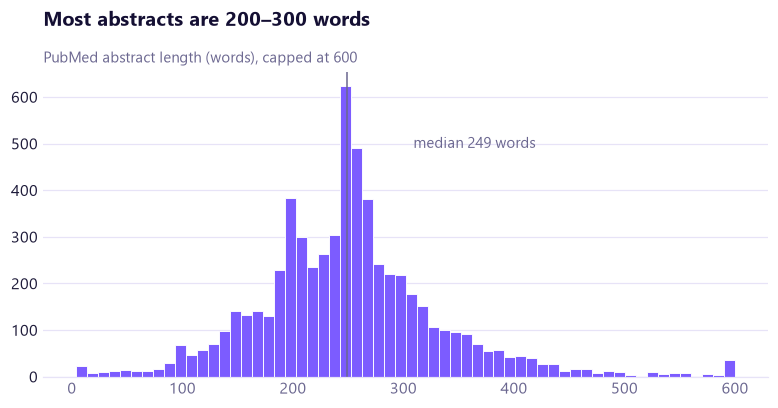

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
words = corpus.loc[corpus["source"] == "pubmed", "n_words"].clip(upper=600)
ax.hist(words, bins=60, color=VIOLET, edgecolor="white", linewidth=0.6)
ax.axvline(words.median(), color=TEXT_2, lw=1)
ax.text(words.median() + 60, ax.get_ylim()[1] * 0.75, f"median {words.median():.0f} words", color=TEXT_2, fontsize=9.5)
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
ax.set_title("Most abstracts are 200–300 words")
subtitle(ax, "PubMed abstract length (words), capped at 600")
viz.save(fig, "06_1_abstract_length")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **~6,200 abstracts** (papers found by several queries are kept once), typically **~250 words** each: about **1.5 million words**, far more than anyone could read.
- The sharp spike at **~250 words** is the typical **journal abstract word limit**: authors write right up to the cap. (Small details like this tell you how the data was produced.)
- The length limit matters later: BERT-style models read at most **512 tokens**, so most abstracts fit in one pass, but long label sections must be **chunked** (notebook 13).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Unicode normalisation: invisible characters

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

Computers store characters as **Unicode code points**. Many look identical but are different: `-` (hyphen), `–` (en dash), `−` (minus); a normal space vs a **non-breaking** or **thin** space; `µ` (micro sign) vs `μ` (Greek mu).
To a computer, `5–10 mg` and `5-10 mg` are **different strings**, so searches, counts and regexes silently miss matches.

**NFKC normalisation** maps "compatibility" characters to a standard form; we add explicit fixes for dashes, spaces and micro signs.

</div>

In [4]:
raw = " ".join(P.load_pubmed()["text"])          # raw abstracts, before normalisation
found = pd.DataFrame([{"character": repr(ch), "name": name, "count": raw.count(ch), "replaced_with": repr(fix)}
                      for ch, fix, name in [(" ", " ", "non-breaking space"), (" ", " ", "thin space"),
                                            ("–", "-", "en dash"), ("−", "-", "minus sign"),
                                            ("µ", "u", "micro sign"), ("μ", "u", "Greek mu"),
                                            ("≥", ">=", "greater-or-equal")]])
show(found, "Look-alike characters hiding in the raw abstracts")

example = "Doses of 5–10 mg (≥ 7 %) reduced HbA1c by −1.5 %."
print("before:", repr(example))
print("after :", repr(P.normalize_unicode(example)))

before: 'Doses of 5–10\xa0mg (≥\u20097\xa0%) reduced HbA1c by −1.5\xa0%.'
after : 'Doses of 5-10 mg (>= 7 %) reduced HbA1c by -1.5 %.'


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Thousands of **thin and non-breaking spaces** and ~2,000 `≥` signs sit inside the raw text. After normalisation, `5–10 mg` and `5-10 mg` are the same string, so every later step (regex, counting, matching to label text) works consistently.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · Regular expressions: pulling facts out of text

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

A **regular expression (regex)** is a pattern language for text. Building blocks:

| Pattern | Meaning | Example |
|---|---|---|
| `\d+` | one or more digits | `15` |
| `(?:\.\d+)?` | optional decimal part | `2.4` |
| `\s?` | optional space | `15mg` / `15 mg` |
| `(?:mg\|mcg\|g)` | one of several words | `mg` |
| `\b` | word boundary | stops `mg` matching inside `mgmt` |

Regex is **fast, transparent and needs no training data**: perfect for well-formatted things like doses, p-values and trial names. It fails on meaning (see the 95% example below), which is where machine learning comes in.

</div>

In [5]:
abstracts = " ".join(corpus.loc[corpus["source"] == "pubmed", "text"])
rows = []
for kind in ["dose", "trial_name", "hba1c", "p_value", "percent"]:
    matches = collections.Counter(m.strip() for m in P.extract(abstracts, kind))
    rows.append({"pattern": kind, "matches": sum(matches.values()),
                 "most_common": ", ".join(f"{k} ({v})" for k, v in matches.most_common(5))})
show(pd.DataFrame(rows), "What the regex patterns find across all abstracts")

pattern,matches,most_common
dose,"4,320","15 mg (514), 2.4 mg (512), 10 mg (290), 5 mg (231), 1 mg (187)"
trial_name,"1,330","SELECT (184), STEP (170), SURMOUNT-1 (110), SURPASS (88), FLOW (77)"
hba1c,809,"HbA1c < 7.0% (26), HbA1c < 7% (23), HbA1c <7% (17), HbA1c <7.0% (14), HbA1c less than 7.0% (11)"
p_value,"4,625","p < 0.001 (680), P < 0.001 (283), p < 0.0001 (194), P < .001 (150), p < 0.05 (144)"
percent,"20,680","95% (4920), 5% (503), 10% (389), 15% (250), 20% (243)"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Doses:** `15 mg` (tirzepatide's top dose) and `2.4 mg` (semaglutide's obesity dose) dominate, so the corpus mirrors the market.
- **Trial names:** SELECT, STEP, SURMOUNT-1 and SURPASS are the landmark programmes reps hear about.
- **HbA1c targets** like `HbA1c < 7%` appear in many forms (`<7%`, `< 7.0%`, `less than 7.0%`), and one pattern catches them all.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out · Regex matches form, not meaning</b>

- The most common "percentage" is **95%**, but almost all are **"95% CI"** (confidence intervals), not results. A regex has no idea of context.
- `SELECT`, `STEP` and `FLOW` are also ordinary English words; in capitals inside abstracts they're nearly always trials, but not always.

Rule of thumb: **regex for format, models for meaning.**

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · Tokenisation: sentences and words

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

**Tokenisation** splits text into units. Splitting on spaces sounds enough, but biomedical text breaks naive rules:
- `HbA1c`, `GLP-1`, `5-mg`, `p<0.001`, `U.S.`, `e.g.` (is that full stop the end of a sentence?)

**Sentence tokenisers** (NLTK's *Punkt*) learn which full stops end sentences. **Word tokenisers** (NLTK, spaCy) use rules for punctuation, contractions and numbers.

</div>

In [6]:
text = "In the U.S., GLP-1 RAs (e.g. tirzepatide 5-mg) cut HbA1c by 2.1% vs. placebo (p<0.001). Nausea wasn't rare."

nlp = P.spacy_nlp()
compare = pd.DataFrame({
    "method": ["str.split()", "NLTK word_tokenize", "spaCy"],
    "tokens": [text.split(), nltk.word_tokenize(text), [t.text for t in nlp(text)]],
})
compare["n_tokens"] = compare["tokens"].str.len()
compare["tokens"] = compare["tokens"].map(lambda t: " | ".join(t))
show(compare, "Same sentence, three word tokenisers")

print("Sentences (NLTK Punkt):")
for s in nltk.sent_tokenize(text):
    print("  •", s)

Sentences (NLTK Punkt):
  • In the U.S., GLP-1 RAs (e.g.
  • tirzepatide 5-mg) cut HbA1c by 2.1% vs. placebo (p<0.001).
  • Nausea wasn't rare.


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- `str.split()` glues punctuation to words (`(e.g.`, `placebo`) and can't separate `wasn't`.
- NLTK and spaCy split punctuation, and handle `wasn't` → `was` + `n't` (keeping the **negation** as its own token).
- **Punkt** correctly keeps `U.S.` and `vs.` inside the sentence, **but wrongly splits after `e.g.`** (inside brackets). Even trained tokenizers make mistakes on real text, so check a sample before trusting any pipeline.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Subword tokenisation: how transformers see words

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Subwords: BPE, WordPiece, SentencePiece</b>

Word-level vocabularies have two problems: they get **huge**, and any new word (`orforglipron`!) is **out-of-vocabulary (OOV)**. Transformers use **subwords**: frequent words stay whole, rare words split into frequent pieces.

| Algorithm | Used by | Idea |
|---|---|---|
| **BPE** (byte-pair encoding) | GPT-2/3/4, Llama | start from characters, repeatedly **merge the most frequent adjacent pair** |
| **WordPiece** | BERT, BiomedBERT | like BPE but merges the pair that most increases the training-data **likelihood**; `##` marks a continuation |
| **SentencePiece** (Unigram) | T5, Gemma | treats text as a raw stream (spaces included); prunes a large vocabulary down |

Below we (1) **train a tiny BPE ourselves** to watch merges happen, then (2) compare real tokenizers on drug names.

</div>

In [7]:
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

# ── Train a toy BPE with only 400 vocabulary entries on our abstracts ───────
toy = Tokenizer(models.BPE(unk_token="[UNK]"))
toy.pre_tokenizer = pre_tokenizers.Whitespace()
toy.train_from_iterator(corpus["text"].str.lower().tolist(),
                        trainers.BpeTrainer(vocab_size=400, special_tokens=["[UNK]"], show_progress=False))

merges = [k for k, _ in sorted(toy.get_vocab().items(), key=lambda kv: kv[1]) if len(k) > 1][:25]
print("First merges learned (most frequent pairs first):", merges)
for w in ["tirzepatide", "semaglutide", "nausea", "orforglipron"]:
    print(f"  {w:<13} → {toy.encode(w).tokens}")

First merges learned (most frequent pairs first): ['[UNK]', 'in', 'ti', 're', 'th', 'on', 'an', 'en', 'er', 'ed', 'al', 'es', 'or', 'as', 'at', 'and', 'is', 'ati', 'ar', 'ic', 'ro', 'de', 'the', 'gl', 'ts']
  tirzepatide   → ['tirzepatide']
  semaglutide   → ['semaglutide']
  nausea        → ['n', 'a', 'use', 'a']
  orforglipron  → ['or', 'for', 'gl', 'i', 'p', 'r', 'on']


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The first merges are pieces of very frequent words (`in`, `ti`, `th`, `er`…).
- Surprise: with only 400 entries, **`tirzepatide` and `semaglutide` are whole tokens**, because in *this* corpus they're among the most frequent words. `nausea` (less frequent) splits into 4 pieces, and the rare `orforglipron` into 7.
- That's the core idea of BPE: **the vocabulary mirrors the training corpus**. The next cell shows the same effect in real tokenizers trained on different text.

</div>

In [8]:
TOKENIZERS = {
    "BERT (general English, WordPiece)":  "bert-base-uncased",
    "GPT-2 (web text, BPE)":              "gpt2",
    "BiomedBERT (PubMed, WordPiece)":     "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext",
}
toks = {name: AutoTokenizer.from_pretrained(path) for name, path in TOKENIZERS.items()}

terms = ["tirzepatide", "semaglutide", "orforglipron", "HbA1c", "nausea", "gastroparesis", "pancreatitis"]
table = pd.DataFrame({name: [" ".join(t.tokenize(w)).replace("Ġ", "") for w in terms] for name, t in toks.items()},
                     index=terms).reset_index(names="term")
show(table, "How each tokenizer splits domain words")

term,"BERT (general English, WordPiece)","GPT-2 (web text, BPE)","BiomedBERT (PubMed, WordPiece)"
tirzepatide,ti ##rz ##ep ##ati ##de,t ir z ep at ide,tir ##ze ##pati ##de
semaglutide,se ##ma ##gl ##uti ##de,se mag l ut ide,sema ##glut ##ide
orforglipron,or ##for ##gli ##pro ##n,or for gl ip ron,orf ##or ##gl ##ipr ##on
HbA1c,h ##ba ##1 ##c,H b A 1 c,hba1c
nausea,nausea,n ause a,nausea
gastroparesis,gas ##tro ##par ##esis,g ast rop ares is,gastro ##par ##esis
pancreatitis,pan ##cre ##ati ##tis,p anc reat itis,pancreatitis


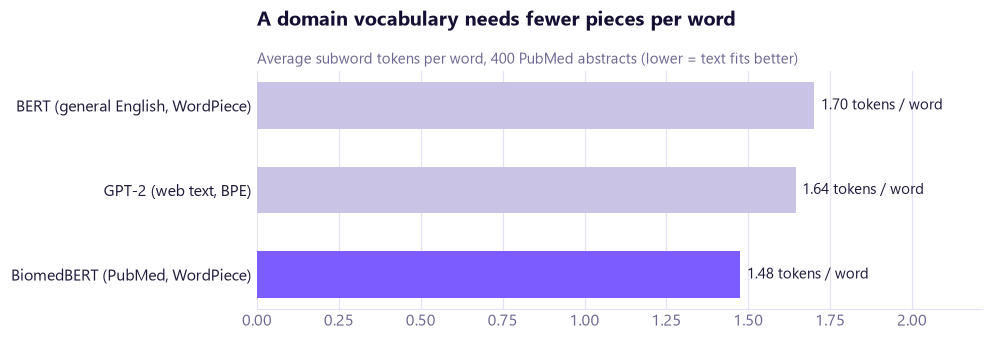

In [9]:
# ── "Fertility": average subword tokens per word on 400 real abstracts ─────
sample = corpus[corpus["source"] == "pubmed"].sample(400, random_state=0)["text"]
n_words = sample.str.split().str.len().sum()
fert = pd.Series({name: sum(len(t.tokenize(x)) for x in sample) / n_words for name, t in toks.items()}).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 2.8))
colors = [VIOLET if "Biomed" in n else MUTED for n in fert.index]
ax.barh(fert.index, fert.values, color=colors, height=0.55)
for y, v in enumerate(fert.values):
    ax.text(v + 0.02, y, f"{v:.2f} tokens / word", va="center", fontsize=9.5, color=TEXT)
ax.set_xlim(0, fert.max() * 1.3)
ax.set_title("A domain vocabulary needs fewer pieces per word")
subtitle(ax, "Average subword tokens per word, 400 PubMed abstracts (lower = text fits better)")
viz.save(fig, "06_2_tokenizer_fertility")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **BiomedBERT**, whose vocabulary was built from PubMed, keeps `hba1c`, `nausea` and `pancreatitis` whole and splits fewer words overall.
- General BERT chops `hba1c` into `h ##ba ##1 ##c`; GPT-2 splits `tirzepatide` into six pieces.
- Lower fertility means **more text fits in the 512-token window** and the model sees meaningful units, one reason domain models (BioBERT, BiomedBERT) win on medical tasks (notebook 11).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · Stop words, stemming and lemmatisation

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

- **Stop words** (`the`, `of`, `and`) are very frequent but carry little topic information, so counting models usually drop them.
  ⚠️ But standard lists include **negations** (`no`, `not`, `without`), and in clinical text *"no nausea"* vs *"nausea"* flips the meaning, so we **keep negations**.
- **Stemming** chops word endings with fixed rules (Porter): fast but crude (`studies → studi`).
- **Lemmatisation** maps a word to its dictionary form using vocabulary and part of speech (`studies → study`, `was → be`).

</div>

In [10]:
words = ["studies", "doses", "injections", "nauseated", "vomiting", "diabetic", "reduced", "patients", "was", "better"]
porter, wordnet = PorterStemmer(), WordNetLemmatizer()
doc = P.spacy_nlp()(" ".join(words))
stem_vs_lemma = pd.DataFrame({
    "word":            words,
    "Porter stem":     [porter.stem(w) for w in words],
    "WordNet lemma":   [wordnet.lemmatize(w) for w in words],
    "spaCy lemma":     [t.lemma_ for t in doc],
    "ours (+ fixes)":  [P.LEMMA_OVERRIDES.get(t.lower_, t.lemma_) for t in doc],
})
show(stem_vs_lemma, "Stemming vs lemmatisation on medical words")

word,Porter stem,WordNet lemma,spaCy lemma,ours (+ fixes)
studies,studi,study,study,study
doses,dose,dos,dose,dose
injections,inject,injection,injection,injection
nauseated,nauseat,nauseated,nauseate,nauseate
vomiting,vomit,vomiting,vomit,vomit
diabetic,diabet,diabetic,diabetic,diabetic
reduced,reduc,reduced,reduced,reduced
patients,patient,patient,patient,patient
was,wa,wa,be,be
better,better,better,well,well


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Porter** produces non-words (`studi`, `diabet`, `reduc`, even `was → wa`). Fine for counting, useless for display.
- **WordNet** without part-of-speech treats every word as a noun: `doses → dos`, `was → wa`.
- **spaCy** uses part of speech (`was → be`) and gets `doses` right in this word list, but turned **`doses` into `dos`** inside a full sentence in section 1: lemmas depend on how the model tags each word in context. It also reads isolated `better` as an adverb (`well`).
- So we add a small **domain override list** (last column), a common, practical fix when a general model meets medical text.

</div>

In [11]:
sentence = "Patients reported no nausea and did not stop treatment, but vomiting was common at higher doses."
show(pd.DataFrame({
    "setting": ["standard stop-word removal", "our clean() (keeps negations)"],
    "tokens":  [" ".join(P.clean(sentence, keep_negations=False)), " ".join(P.clean(sentence))],
}), "Why negations must survive cleaning")

setting,tokens
standard stop-word removal,patient report nausea stop treatment vomiting common high dose
our clean() (keeps negations),patient report no nausea not stop treatment vomiting common high dose


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Standard stop-word removal turns *"no nausea… did not stop"* into **"nausea… stop"**, the opposite meaning. Keeping `no` and `not` preserves it.
This matters a lot for visit-note classification (notebook 07) and side-effect detection (notebook 12).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 7 · Grammar: part-of-speech tags, dependency parsing and NER

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

- **POS tagging** labels each token's grammatical role (NOUN, VERB, ADJ…).
- **Dependency parsing** links words into a tree: *who did what to whom*. Here it tells us **which word "not" negates**.
- **Named-entity recognition (NER)** finds names of things (people, organisations, dates…).
spaCy's small English model does all three, but it was trained on news and web text, not medicine.

</div>

In [12]:
doc = P.spacy_nlp()("Dr. Patel said the patient did not tolerate Mounjaro 5 mg because of severe nausea.")
display(show(pd.DataFrame([{"token": t.text, "POS": t.pos_, "dependency": t.dep_, "head": t.head.text} for t in doc]),
             "POS and dependency parse"))
show(pd.DataFrame([{"entity": e.text, "label": e.label_, "spaCy meaning": spacy.explain(e.label_)} for e in doc.ents]),
     "General-purpose NER on a clinical sentence")

token,POS,dependency,head
Dr.,PROPN,compound,Patel
Patel,PROPN,nsubj,said
said,VERB,ROOT,said
the,DET,det,patient
patient,NOUN,nsubj,tolerate
did,AUX,aux,tolerate
not,PART,neg,tolerate
tolerate,VERB,ccomp,said
Mounjaro,PROPN,nmod,mg
5,NUM,nummod,mg


entity,label,spaCy meaning
Patel,PERSON,"People, including fictional"
Mounjaro 5,PERSON,"People, including fictional"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The parse links **`not` → `tolerate`** (dependency `neg`), so the model knows the *tolerating* was negated: the basis for negation-aware side-effect detection.
- General NER correctly finds `Patel` as a PERSON but also labels **`Mounjaro 5` as a PERSON**, and doesn't recognise *nausea* as a side effect at all.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Why domain models matter</b>

General-purpose NLP models are good at grammar but **don't know medicine**. That's why notebook 12 fine-tunes a biomedical model to tag **drugs, doses, side effects and competitor brands**.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 8 · n-grams and collocations

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

An **n-gram** is a sequence of *n* tokens: unigrams (`weight`), bigrams (`weight loss`), trigrams (`type 2 diabetes`).
**Frequent** bigrams are often boring (`of the`). **Collocations** are word pairs that occur together **more than chance**, measured by **PMI** (pointwise mutual information):

$$PMI(x, y) = \log_2 \frac{P(x, y)}{P(x)\,P(y)}$$

High PMI = the pair is a real "phrase". PMI over-rewards rare pairs, so we require a minimum frequency.

</div>

In [13]:
token_lists = [P.clean(t, lemmatize=False) for t in corpus.loc[corpus["source"] == "pubmed", "text"].sample(2500, random_state=1)]
finder = BigramCollocationFinder.from_documents(token_lists)
finder.apply_freq_filter(30)                                  # ignore pairs seen fewer than 30 times
measures = BigramAssocMeasures()

freq = [" ".join(b) for b, _ in finder.ngram_fd.most_common(12)]
pmi = [" ".join(b) for b in finder.nbest(measures.pmi, 12)]
show(pd.DataFrame({"most frequent bigrams": freq, "highest-PMI bigrams (freq ≥ 30)": pmi}),
     "Frequency vs PMI (stop words removed, 2,500 abstracts)")

most frequent bigrams,highest-PMI bigrams (freq ≥ 30)
weight loss,novo nordisk
95 ci,google scholar
glucagon like,atrial fibrillation
type diabetes,suicidal ideation
receptor agonists,sleeve gastrectomy
like peptide-1,glomerular filtration
peptide-1 receptor,homa ir
glp-1 ras,dipeptidyl peptidase-4
glp-1 receptor,albumin creatinine
body weight,randomly assigned


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Frequency** surfaces the topic's backbone (`weight loss`, `type diabetes`, `glp-1 receptor`) plus noise like `95 ci`.
- **PMI** surfaces tight phrases that should be treated as **one unit**: organisations (`novo nordisk`), databases (`google scholar`), and clinical terms (`atrial fibrillation`, `suicidal ideation`, `sleeve gastrectomy`, `glomerular filtration`).
- In notebook 07 we'll add bigrams as features so *"weight loss"* isn't split into two unrelated words.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 9 · Zipf's law: why text is always sparse

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

**Zipf's law:** a word's frequency is roughly inversely proportional to its rank, *f ∝ 1 / rank*. On a log–log plot that's a straight line with slope ≈ −1.
Consequence: a **few words are everywhere** and **most words are rare**. Half the vocabulary appears only once or twice, so document-term matrices are **sparse** (mostly zeros), which motivates TF-IDF weighting and, later, dense embeddings.

</div>

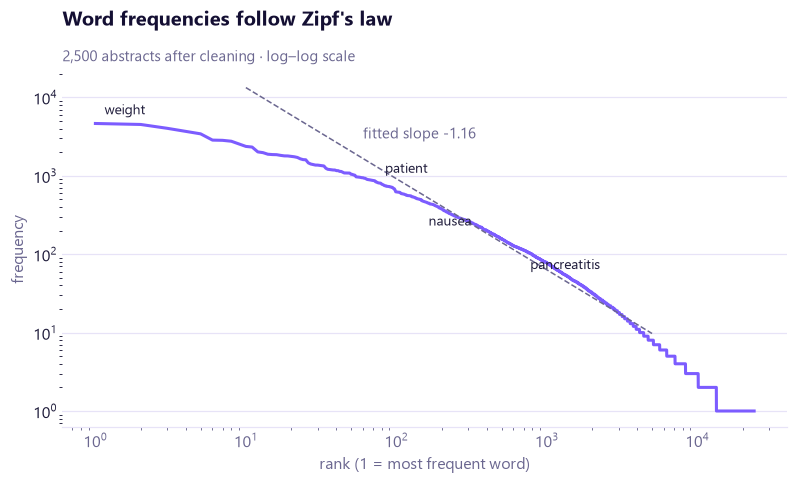

Vocabulary: 23,852 words · seen only once: 10,478 (44%)


In [14]:
counts = collections.Counter(w for toks in token_lists for w in toks)
freqs = np.array(sorted(counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
mask = (ranks >= 10) & (ranks <= 5000)
slope, intercept = np.polyfit(np.log10(ranks[mask]), np.log10(freqs[mask]), 1)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.loglog(ranks, freqs, color=VIOLET, lw=2)
ax.loglog(ranks[mask], 10 ** (intercept + slope * np.log10(ranks[mask])), color=TEXT_2, lw=1, ls="--")
ax.text(60, 10 ** (intercept + slope * np.log10(60)) * 1.8, f"fitted slope {slope:.2f}", color=TEXT_2, fontsize=9.5)
for w, offset in [("weight", (6, 6)), ("patient", (6, 6)), ("nausea", (-50, 10)), ("pancreatitis", (8, -14))]:
    if w in counts:
        r = int(np.where(freqs == counts[w])[0][0]) + 1
        ax.annotate(w, (r, counts[w]), xytext=offset, textcoords="offset points", fontsize=9, color=TEXT)
ax.grid(axis="both", which="major")
ax.set_xlabel("rank (1 = most frequent word)"); ax.set_ylabel("frequency")
ax.set_title("Word frequencies follow Zipf's law")
subtitle(ax, "2,500 abstracts after cleaning · log–log scale")
viz.save(fig, "06_3_zipf")
plt.show()

hapax = sum(1 for v in counts.values() if v == 1)
print(f"Vocabulary: {len(counts):,} words · seen only once: {hapax:,} ({100 * hapax / len(counts):.0f}%)")

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The curve is close to a straight line on log–log axes, with a slope near −1: **Zipf's law holds** even in technical medical text.
- **44% of the vocabulary appears only once** (*hapax legomena*). Any count-based model must cope with this long tail of rare words.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 10 · Summary

</div>

<div style="border-left:6px solid #14B8A6; background:#E9FBF8; color:#134E4A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🛠️ What the next code does</b>

The whole pipeline in one call, `P.clean(text)`: normalise Unicode → spaCy tokenise → lemmatise (with domain fixes) → lower-case → drop punctuation and stop words **but keep negations**.

</div>

In [15]:
demo = "Patients didn’t report nausea at 5–10 mg; pancreatitis occurred in ≥1% (p<0.05)."
print("raw    :", demo)
print("clean():", P.clean(demo))

raw    : Patients didn’t report nausea at 5–10 mg; pancreatitis occurred in ≥1% (p<0.05).
clean(): ['patient', 'not', 'report', 'nausea', '10', 'mg', 'pancreatitis', 'occur', 'p<0.05']


<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. spaCy's small English model isn't biomedical: lemmas and entities have errors on drug names (we patch a few; scispaCy / biomedical models do better).
2. Regex patterns are written for this corpus; new formats (`15mg/wk`) need new patterns and tests.
3. Heavy cleaning is **wrong for transformers**, which expect raw text. Keep both versions.
4. Abstracts are written by researchers; **visit notes** (notebook 09) will be shorter, informal and full of abbreviations.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** a reusable preprocessing module + the cleaned research/label corpus (`data/02_interim/nlp_corpus.parquet`).
**Next:** notebook 07, **Bag-of-Words and TF-IDF** with classical classifiers, the baseline every transformer must beat.

**Interview questions you can now answer**
- *Why normalise Unicode?* Look-alike characters (en dash, thin space, µ vs μ) silently break matching and counting.
- *Regex or ML?* Regex for format (doses, p-values), ML for meaning (the "95% CI" trap).
- *What is BPE / WordPiece and why subwords?* Merge frequent pairs into a fixed vocabulary, so there are no out-of-vocabulary words; `##` marks continuations in WordPiece.
- *Why use a biomedical tokenizer?* Fewer pieces per word (BiomedBERT keeps `hba1c` whole), so more meaning per 512-token window.
- *Stemming vs lemmatisation?* Rules that chop vs dictionary + POS; lemmas are real words but slower and can still err (`doses → dos`).
- *Why keep negations?* "no nausea" ≠ "nausea": dropping `no` flips clinical meaning.
- *What is PMI?* How much more often two words co-occur than chance; finds real phrases.
- *What does Zipf's law imply?* Few frequent words, a long tail of rare ones, so sparse matrices and the need for TF-IDF and embeddings.

</div>